# Проверка статистических гипотез

# Критерии согласия (Goodness-of-fit тесты)

**Goodness-of-fit** (или *критерии согласия*) — это серия статистических тестов, предназначенных для проверки гипотезы о том, что исследуемая выборка получена из определенного теоретического распределения. Эти критерии позволяют проверить, насколько хорошо наблюдаемые данные соответствуют предполагаемому закону распределения.

## Критерий согласия Пирсона (Хи-квадрат)

**Критерий согласия Пирсона** (Pearson Chi-Square Test) является одним из наиболее популярных критериев согласия. Он используется для сравнения наблюдаемых частот с ожидаемыми частотами, чтобы определить, насколько хорошо данные соответствуют предполагаемому распределению.

Критерий основан на статистике:
$$\chi^2 = \sum_{i=1}^{k} \frac{(O_i - E_i)^2}{E_i}$$
где:
- $O_i$ — наблюдаемая частота в i-й категории
- $E_i$ — ожидаемая частота в i-й категории
- $k$ — количество категорий

## Критерий Колмогорова-Смирнова

**Критерий Колмогорова-Смирнова** предназначен для проверки совокупностей данных, измеренных в количественной шкале. Для большей достоверности объем выборки должен быть достаточно большим: $n \geq 50$.

Статистика критерия имеет вид:
$$D_n = \sup_x |F_n(x) - F(x)|$$
где:
- $\sup$ — точная верхняя грань (супремум)
- $F_n(x)$ — эмпирическая функция распределения
- $F(x)$ — теоретическая функция распределения

## Критерий Колмогорова-Смирнова-Лиллиефорса

В случае проверки гипотезы о нормальности распределения, когда параметры нормального закона оцениваются по самой выборке, используется **модифицированный критерий Колмогорова-Смирнова-Лиллиефорса**.


$$D_n^* = D_n(\sqrt{n} - 0.01 + \frac{0.85}{\sqrt{n}})$$

*Важное замечание: В стандартных статистических источниках модификация Лиллиефорса обычно предполагает использование специальных таблиц критических значений, а не простое преобразование статистики $D_n$*

## Критерий Шапиро-Уилка

**Критерий Шапиро-Уилка** используется исключительно для проверки гипотезы о том, что случайная величина распределена по нормальному закону. Это один из наиболее мощных критериев для проверки нормальности.

Статистика критерия имеет вид:
$$W = \frac{1}{s^2} \left[ \sum_{i=1}^n a_{n-i+1} (x_{n-i+1} - x_i) \right]^2$$
где:
- $s^2 = \sum_{i=1}^n (x_i - \overline{x})^2$ — выборочная дисперсия
- $\overline{x} = \frac{1}{n} \sum_{i=1}^n x_i$ — выборочное среднее
- $a_{n-i+1}$ — табличные коэффициенты

Значения коэффициентов $a_{n-i+1}$ и критические значения статистики $W(\alpha)$ определяются по специальным таблицам. Если $W < W(\alpha)$, то нулевая гипотеза о нормальности распределения отклоняется при уровне значимости $\alpha$.

*Примечание: Критерий Шапиро-Уилка особенно эффективен для выборок небольшого и среднего размера (до 50 наблюдений), в отличие от критерия Колмогорова-Смирнова, который требует больших выборок.*

# Практическое применение критериев согласия в Python

## Подготовка среды и данных

Для работы с статистическими тестами в Python нам понадобятся следующие библиотеки:



In [ ]:
# Импорт необходимых библиотек

import numpy as np # Для численных вычислений и работы с массивами
import matplotlib.pyplot as plt  # Для построения графиков и визуализации
import scipy.stats as stats  # Для статистических тестов и распределений
from scipy.stats import norm, beta, chi2  # Конкретные распределения для анализа
from statsmodels.stats.diagnostic import lilliefors  # Специальный тест на нормальность
import seaborn as sns  # Для улучшенной визуализации статистических данных

# Размер графиков: 10×6 дюймов
plt.rcParams['figure.figsize'] = (10, 6)

# Размер шрифта: 12 пунктов
plt.rcParams['font.size'] = 12


print("Библиотеки успешно загружены")

Библиотеки успешно загружены


Создадим тестовые выборки для демонстрации работы критериев:

In [ ]:
# Инициализация генератора случайных чисел для воспроизводимости результатов

np.random.seed(1000) # Фиксируем seed для получения одинаковых результатов при каждом запуске
N = 1000  # Размер выборки

# Создание тестовых выборок:

# X - нормальное распределение N(μ=5, σ=2)
X = np.random.normal(loc=5, scale=2, size=N)

# Y - бета-распределение Beta(α=2, β=2)
Y = np.random.beta(a=2, b=2, size=N)

# Z - смесь нормального и бета-распределения (объединение)
Z = np.concatenate([X, Y])


print(f"Созданы выборки: X (нормальная) размер {len(X)}, Y (бета) размер {len(Y)}, Z (смесь) размер {len(Z)}")

Созданы выборки: X (нормальная) размер 1000, Y (бета) размер 1000, Z (смесь) размер 2000


## Визуализация распределений

Перед применением статистических тестов полезно визуализировать данные:

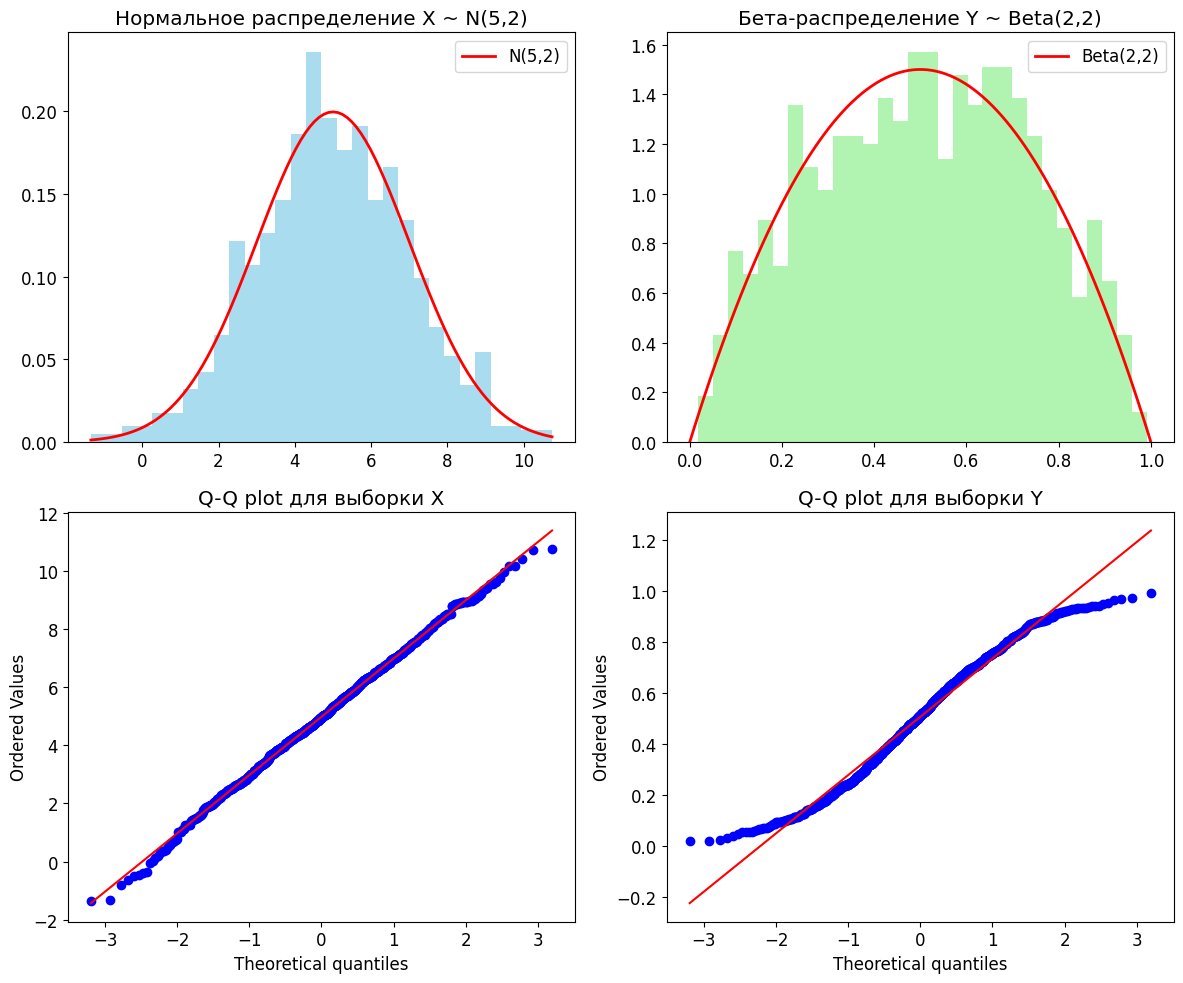

In [ ]:
# Построение графиков распределений

# Создаем фигуру с сеткой 2x2 графиков размером 12x10 дюймов
# axes - двумерный массив объектов Axes для обращения к каждому графику
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Гистограмма нормального распределения

# bins=30 - разбиваем данные на 30 интервалов для оптимального отображения формы распределения
# density=True - нормируем гистограмму так, чтобы площадь под ней равнялась 1 (преобразование в плотность вероятности)
# alpha=0.7 - задаем полупрозрачность для лучшего визуального восприятия
# color='skyblue' - устанавливаем голубой цвет столбцов гистограммы

axes[0,0].hist(X, bins=30, density=True, alpha=0.7, color='skyblue')

# Создаем равномерно распределенные точки от минимального до максимального значения выборки X
# 100 точек обеспечивают плавное отображение теоретической кривой
x_range = np.linspace(np.min(X), np.max(X), 100)

# Строим теоретическую кривую нормального распределения с параметрами μ=5, σ=2
# 'r-' - красная сплошная линия, linewidth=2 - толщина линии 2 пункта
# norm.pdf() вычисляет значения плотности вероятности в точках x_range
axes[0,0].plot(x_range, norm.pdf(x_range, 5, 2), 'r-', linewidth=2, label='N(5,2)')

# Устанавливаем заголовок графика
axes[0,0].set_title('Нормальное распределение X ~ N(5,2)')

# Добавляем легенду на график
axes[0,0].legend()

# Гистограмма бета-распределения
axes[0,1].hist(Y, bins=30, density=True, alpha=0.7, color='lightgreen')

# Создаем 100 равномерно распределенных точек от 0 до 1
y_range = np.linspace(0, 1, 100)

# Строим теоретическую кривую бета-распределения
axes[0,1].plot(y_range, beta.pdf(y_range, 2, 2), 'r-', linewidth=2, label='Beta(2,2)')
axes[0,1].set_title('Бета-распределение Y ~ Beta(2,2)')
axes[0,1].legend()

# Q-Q plot для нормального распределения
# По оси X: теоретические квантили нормального распределения
# По оси Y: эмпирические квантили выборки X
# Точки, лежащие на диагональной линии, свидетельствуют о нормальности распределения
stats.probplot(X, dist="norm", plot=axes[1,0])
axes[1,0].set_title('Q-Q plot для выборки X')

# Q-Q plot для бета-распределения
# Поскольку Y имеет бета-распределение, точки будут отклоняться от диагональной линии
# Это демонстрирует, что распределение не является нормальным
stats.probplot(Y, dist="norm", plot=axes[1,1])
axes[1,1].set_title('Q-Q plot для выборки Y')

#  Автоматически настраиваем расположение всех элементов графиков, чтобы они не перекрывали друг друга и были хорошо читаемы
plt.tight_layout()
plt.show()

## Критерий Колмогорова-Смирнова

Применим критерий Колмогорова-Смирнова для проверки соответствия распределений:

In [ ]:
print("\n Критерий Колмогорова-Смирнова ")

# Критерий Колмогорова-Смирнова: сравнивает эмпирическую функцию распределения с теоретической
# H0: выборка X происходит из нормального распределения с параметрами μ=5, σ=2
# H1: выборка X не происходит из указанного нормального распределения
ks_stat_x, ks_p_x = stats.kstest(X, 'norm', args=(5, 2))

# ks_stat_x - статистика критерия Dn (максимальное расстояние между эмпирической и теоретической функциями распределения)
# ks_p_x - p-value (вероятность получить такие или более крайние результаты при условии, что H0 верна)
print(f"X ~ N(5,2): D={ks_stat_x:.6f}, p-value={ks_p_x:.4f}")

#если p-value > 0.05, нет оснований отвергать H0 (распределение соответствует нормальному)

# Проверка выборки Y на соответствие бета-распределению
# H0: выборка Y происходит из бета-распределения с параметрами α=2, β=2
# H1: выборка Y не происходит из указанного бета-распределения
ks_stat_y_beta, ks_p_y_beta = stats.kstest(Y, 'beta', args=(2, 2))

print(f"Y ~ Beta(2,2): D={ks_stat_y_beta:.6f}, p-value={ks_p_y_beta:.4f}")

# Интерпретация: большой p-value (> 0.05) свидетельствует о соответствии бета-распределению

# Сравнение двух выборок (X и Y) с помощью двухвыборочного критерия Колмогорова-Смирнова
# H0: выборки X и Y происходят из одного и того же распределения
# H1: выборки X и Y происходят из разных распределений
ks_stat_xy, ks_p_xy = stats.ks_2samp(X, Y)

# Статистика Dn - максимальное расстояние между двумя эмпирическими функциями распределения
# p-value показывает вероятность наблюдать такие различия, если бы выборки были из одного распределения
print(f"X и Y из одного распределения: D={ks_stat_xy:.6f}, p-value={ks_p_xy:.4f}")



 Критерий Колмогорова-Смирнова 
X ~ N(5,2): D=0.014931, p-value=0.9766
Y ~ Beta(2,2): D=0.031198, p-value=0.2789
X и Y из одного распределения: D=0.977000, p-value=0.0000


# Пример анализа результатов

**Выборка X:**

`D = 0.014931` - очень маленькое значение, что указывает на минимальное
расхождение между эмпирическим и теоретическим распределениями.

`p-value = 0.9766` - значительно превышает уровень значимости 0.05

**Вывод:** Нет оснований отвергать нулевую гипотезу. Выборка X действительно соответствует нормальному распределению N(5,2).



**Выборка Y:**

`D = 0.031198` - небольшое значение, свидетельствующее о хорошем соответствии.

`p-value = 0.2789 > 0.05` - статистически не значимо.

**Вывод:** Нет оснований отвергать нулевую гипотезу. Выборка Y действительно соответствует бета-распределению Beta(2,2).



**Сравнение выборок:**

`Статистика D = 0.977` - очень большое значение, близкое к максимально возможному 1.0, что указывает на кардинальное различие распределений.

`p-value = 0.0000` - практически нулевая вероятность, что такие различия возникли случайно.

**Вывод:** Отвергаем нулевую гипотезу. Выборки X и Y происходят из разных распределений.



*Комментарий:*
- Функция `kstest` из scipy.stats реализует критерий Колмогорова-Смирнова
- Аргумент `args` передает параметры теоретического распределения
- Для нормального распределения: `args=(mean, std)`
- Для бета-распределения: `args=(alpha, beta)`
- Малое p-value (< 0.05) указывает на отклонение нулевой гипотезы о соответствии распределений

## Критерий Колмогорова-Смирнова-Лиллиефорса

Критерий Лиллиефорса является модификацией критерия Колмогорова-Смирнова для проверки нормальности, когда параметры оцениваются по выборке:

In [ ]:
print("\n Критерий Колмогорова-Смирнова-Лиллиефорса ")

# Критерий Лиллиефорса для проверки нормальности
# В отличие от KS-теста, здесь параметры нормального распределения оцениваются по данным
lillie_stat_x, lillie_p_x = lilliefors(X, dist='norm')
print(f"Лиллиефорс для X (нормальность): D={lillie_stat_x:.6f}, p-value={lillie_p_x:.4f}")

lillie_stat_y, lillie_p_y = lilliefors(Y, dist='norm')
print(f"Лиллиефорс для Y (нормальность): D={lillie_stat_y:.6f}, p-value={lillie_p_y:.4f}")


 Критерий Колмогорова-Смирнова-Лиллиефорса 
Лиллиефорс для X (нормальность): D=0.015526, p-value=0.8654
Лиллиефорс для Y (нормальность): D=0.044161, p-value=0.0010


*Комментарий:*
- Критерий Лиллиефорса специально разработан для проверки нормальности.
- В отличие от обычного KS-теста, использует скорректированные критические значения.
- Функция `lilliefors` из statsmodels автоматически оценивает параметры нормального распределения по данным.


## Критерий Шапиро-Уилка

Критерий Шапиро-Уилка является одним из наиболее мощных тестов для проверки нормальности:

In [ ]:
print("\n Критерий Шапиро-Уилка ")

# Проверка нормальности для выборки X
shapiro_stat_x, shapiro_p_x = stats.shapiro(X)
print(f"Шапиро-Уилк для X: W={shapiro_stat_x:.5f}, p-value={shapiro_p_x:.4f}")

# Проверка нормальности для выборки Y
shapiro_stat_y, shapiro_p_y = stats.shapiro(Y)
print(f"Шапиро-Уилк для Y: W={shapiro_stat_y:.5f}, p-value={shapiro_p_y:.4e}")

# Интерпретация результатов
alpha = 0.05
print(f"\nИнтерпретация (уровень значимости α={alpha}):")
print(f"Выборка X: {'нормальное распределение' if shapiro_p_x > alpha else 'не нормальное распределение'}")
print(f"Выборка Y: {'нормальное распределение' if shapiro_p_y > alpha else 'не нормальное распределение'}")


 Критерий Шапиро-Уилка 
Шапиро-Уилк для X: W=0.99869, p-value=0.6833
Шапиро-Уилк для Y: W=0.97962, p-value=1.2764e-10

Интерпретация (уровень значимости α=0.05):
Выборка X: нормальное распределение
Выборка Y: не нормальное распределение


*Комментарий:*
- Критерий Шапиро-Уилка особенно эффективен для выборок небольшого и среднего размера
- Статистика W близка к 1 при нормальном распределении
- Тест чувствителен к отклонениям в хвостах распределения
- Рекомендуется для выборок размером до 5000 наблюдений

## Критерий Пирсона (Хи-квадрат)

Реализация критерия согласия Пирсона для проверки соответствия наблюдаемых частот теоретическому распределению:

In [ ]:
print("\n Критерий Пирсона (Хи-квадрат) ")

# Создание интервалов для критерия хи-квадрат
def pearson_chi2_test(data, distribution='norm', *args):
    """
    Реализация критерия Пирсона для проверки согласия с распределением
    """
    # Разбиение данных на интервалы (используем правило Стерджеса)
    n_bins = int(1 + 3.322 * np.log(len(data)))

    # Построение гистограммы: получаем наблюдаемые частоты и границы интервалов
    observed_freq, bin_edges = np.histogram(data, bins=n_bins, density=False)

    # Расчет теоретических вероятностей для каждого интервала
    if distribution == 'norm':

        # Проверка на соответствие нормальному распределению
        if args:
            # Если параметры переданы явно
            mu, sigma = args # mu - математическое ожидание, sigma - стандартное отклонение
        else:
            # Если параметры не заданы - оцениваем по выборке
            mu, sigma = np.mean(data), np.std(data)

        # Вычисляем значения функции распределения cdf на границах интервалов
        # cdf(x) = P(X ≤ x) - вероятность того, что случайная величина примет значение ≤ x
        cdf_values = norm.cdf(bin_edges, mu, sigma)

    elif distribution == 'beta':
        # Параметры бета-распределения
        if args:
            a, b = args
        else:
            # Метод моментов для оценки параметров бета-распределения
            mean_val = np.mean(data)
            var_val = np.var(data)

            # Решение системы уравнений для нахождения a и b через метод моментов
            a = mean_val * (mean_val * (1 - mean_val) / var_val - 1)
            b = (1 - mean_val) * (mean_val * (1 - mean_val) / var_val - 1)

        cdf_values = beta.cdf(bin_edges, a, b)

    # Теоретические вероятности для интервалов
    theoretical_probs = np.diff(cdf_values)

     # Ожидаемые частоты = теоретические вероятности × объем выборки
    theoretical_freq = theoretical_probs * len(data)

    # Критерий хи-квадрат (объединяем интервалы с малыми ожидаемыми частотами)
    # Требование критерия: ожидаемая частота в каждом интервале должна быть ≥ 5
    # В противном случае критерий теряет надежность
    mask = theoretical_freq >= 5
    if np.sum(mask) < 2:

        # Если слишком много малых частот, уменьшаем количество интервалов
        return pearson_chi2_test(data, distribution, *args)

    # Суммирование только по интервалам с достаточными ожидаемыми частотами (mask)
    chi2_stat = np.sum((observed_freq[mask] - theoretical_freq[mask])**2 / theoretical_freq[mask])

    # df = (количество интервалов) - 1 - (количество оцененных параметров)
    df = np.sum(mask) - 1 - len(args)
    p_value = 1 - chi2.cdf(chi2_stat, df)

    return chi2_stat, p_value, df

# Применение критерия Пирсона для выборки X (нормальное распределение)
chi2_stat_x, chi2_p_x, df_x = pearson_chi2_test(X, 'norm', 5, 2)
print(f"Пирсон для X ~ N(5,2): χ²={chi2_stat_x:.4f}, p-value={chi2_p_x:.4f}, df={df_x}")

# Применение критерия Пирсона для выборки Y (бета-распределение)
chi2_stat_y, chi2_p_y, df_y = pearson_chi2_test(Y, 'beta', 2, 2)
print(f"Пирсон для Y ~ Beta(2,2): χ²={chi2_stat_y:.4f}, p-value={chi2_p_y:.4f}, df={df_y}")

# Проверка нормальности для Y с помощью критерия Пирсона
chi2_stat_y_norm, chi2_p_y_norm, df_y_norm = pearson_chi2_test(Y, 'norm')
print(f"Пирсон для Y (нормальность): χ²={chi2_stat_y_norm:.4f}, p-value={chi2_p_y_norm:.4f}, df={df_y_norm}")


 Критерий Пирсона (Хи-квадрат) 
Пирсон для X ~ N(5,2): χ²=12.1145, p-value=0.6703, df=15
Пирсон для Y ~ Beta(2,2): χ²=23.6793, p-value=0.2567, df=20
Пирсон для Y (нормальность): χ²=78.2287, p-value=0.0000, df=22


Кроме того, критерий Пирсона доступен в библиотеке **SciPy**, в модуле `scipy.stats`. Для проверки согласия с теоретическим распределением используется функция `chisquare()`, а для анализа таблиц сопряжённости — функция `chi2_contingency()`. Обе функции позволяют вычислить статистику хи-квадрат и соответствующие значения p-value. Однако в данном случае нам все равно предстоит получить эмпирические и теоретические частоты. И как демонстрация сложности с практическим применением критерия рассмотрим вариант расчета теоерических частот на основе формальной вероятности попасть в заданный интервал:

$$
p_{th} = F(e_{i+1}) - F(e_i)
$$

где $e_{i+1}$ и $e_i$ - границы $i-$го интервала

$$
E_i = p_{th}*n
$$

In [ ]:
# Проверка нормальности для выборки X

def data_prepare_for_pearson(data, distribution="norm", args=None):
    # Разбиение данных на интервалы (правило Стерджеса)
    n_bins = int(1 + 3.322 * np.log(len(data)))
    observed_freq, bin_edges = np.histogram(data, bins=n_bins, density=False)

    # Расчет теоретических вероятностей и частот
    theoretical_freq = np.zeros(n_bins)

    if distribution == 'norm':
        if args:
            mu, sigma = args
        else:
            mu, sigma = np.mean(data), np.std(data)

        # Вычисляем вероятности попадания в каждый интервал
        cdf_values = norm.cdf(bin_edges, mu, sigma)

    elif distribution == 'beta':
        if args:
            a, b = args
        else:
            # Используем метод моментов для оценки параметров
            a, b, _, _ = beta.fit(data, method='MM')  # method='MM' можно заменить на 'MLE'

        # Вычисляем вероятности для бета-распределения
        cdf_values = beta.cdf(bin_edges, a, b)

    else:
        raise ValueError("Распределение не поддерживается")

    # Расчет теоретических частот
    for i in range(n_bins):
        p = cdf_values[i+1] - cdf_values[i]  # Вероятность попадания в интервал
        theoretical_freq[i] = p * len(data)   # Теоретическая частота

    return observed_freq, theoretical_freq, bin_edges

X_observed_freq, X_theoretical_freq, _ = data_prepare_for_pearson(X, "norm")

chisquare_stat_x, chisquare_p_x = stats.chisquare(X_observed_freq, X_theoretical_freq,
                                                  sum_check=False)

print(f"Тест Пирсона для X: chi2={chisquare_stat_x:.5f}, p-value={chisquare_p_x:.4f}")

Y_observed_freq, Y_theoretical_freq, _ = data_prepare_for_pearson(Y, "beta")
# Проверка нормальности для выборки Y
chisquare_stat_y, chisquare_p_y = stats.chisquare(Y_observed_freq, X_theoretical_freq,
                                                  sum_check=False)
print(f"Тест Пирсона для Y: chi2={chisquare_stat_y:.5f}, p-value={chisquare_p_y:.4e}")

# Интерпретация результатов
alpha = 0.05
print(f"\nИнтерпретация (уровень значимости α={alpha}):")
print(f"Выборка X: {'нормальное распределение' if chisquare_p_x > alpha else 'не нормальное распределение'}")
print(f"Выборка Y: {'нормальное распределение' if chisquare_p_y > alpha else 'не нормальное распределение'}")

23
Тест Пирсона для X: chi2=19.30628, p-value=0.6263
Тест Пирсона для Y: chi2=857.45295, p-value=3.7907e-167

Интерпретация (уровень значимости α=0.05):
Выборка X: нормальное распределение
Выборка Y: не нормальное распределение


Но можно записать и проще:

In [ ]:
observed_freq, bin_edges = np.histogram(X, bins=23)
theoretical_freq = len(X) * np.diff(norm.cdf(bin_edges, 5, 2))
chi2_stat, p_value = stats.chisquare(observed_freq, theoretical_freq, sum_check=False)
print(f"Тест Пирсона для X: chi2={chi2_stat:.5f}, p-value={p_value:.4f}")

Тест Пирсона для X: chi2=19.58808, p-value=0.6088


Обратите внимани, для всех трех вариантов мы получили хоть и схожие, но отличающиеся результаты, что может привести к плохой воспроизводимости исследованией с применением этого теста.

*Комментарий:*
- Критерий Пирсона основан на сравнении наблюдаемых и ожидаемых частот
- Требует группировки данных в интервалы
- Чувствителен к выбору количества интервалов
- Рекомендуется иметь не менее 5 ожидаемых наблюдений в каждой группе

## Сравнительный анализ критериев

Проведем сравнительный анализ всех критериев для наглядности:

Для выборки X (нормальное распределение):
  Колмогоров-Смирнов: p-value = 0.9766
  Лиллиефорс: p-value = 0.8654
  Шапиро-Уилк: p-value = 0.6833
  Пирсон (хи-квадрат): p-value = 0.6703


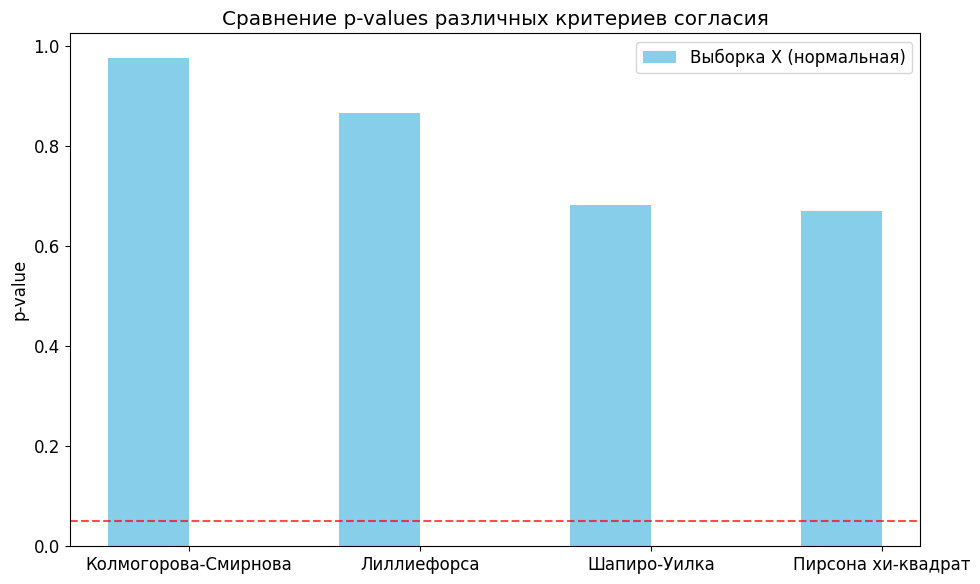

In [ ]:

print("Для выборки X (нормальное распределение):")
print(f"  Колмогоров-Смирнов: p-value = {ks_p_x:.4f}")
print(f"  Лиллиефорс: p-value = {lillie_p_x:.4f}")
print(f"  Шапиро-Уилк: p-value = {shapiro_p_x:.4f}")
print(f"  Пирсон (хи-квадрат): p-value = {chi2_p_x:.4f}")



# Визуализация p-values для сравнения мощности критериев
tests = ['Колмогорова-Смирнова', 'Лиллиефорса', 'Шапиро-Уилка', 'Пирсона хи-квадрат']
p_values_x = [ks_p_x, lillie_p_x, shapiro_p_x, chi2_p_x]

x = np.arange(len(tests))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, p_values_x, width, label='Выборка X (нормальная)', color='skyblue')

ax.set_ylabel('p-value')
ax.set_title('Сравнение p-values различных критериев согласия')
ax.set_xticks(x)
ax.set_xticklabels(tests)
ax.legend()
ax.axhline(y=0.05, color='r', linestyle='--', alpha=0.7, label='α=0.05')

plt.tight_layout()
plt.show()

## Рекомендации по применению критериев

На основе проведенного анализа можно сформулировать следующие рекомендации:

- **Для проверки нормальности** предпочтительнее использовать критерий Шапиро-Уилка или Лиллиефорса
- **Для больших выборок** (n > 50) подходит критерий Колмогорова-Смирнова
- **Для проверки соответствия любым распределениям** используется критерий Пирсона (хи-квадрат)
- **Критерий Лиллиефорса** следует применять когда параметры нормального распределения неизвестны и оцениваются по выборке

- Все критерии чувствительны к объему выборки - с ростом n увеличивается мощность тестов!